In [ ]:
import os, sys, glob, json, hashlib, urllib.request, tarfile, zipfile
from google.colab import drive
drive.mount('/content/drive')
WORK, CODE = '/content/drive/MyDrive/scBERT_run', '/content'
DATA, RES = f'{WORK}/data', f'{WORK}/results'
os.makedirs(DATA, exist_ok=True); os.makedirs(RES, exist_ok=True)
os.chdir(CODE)
REPO = f'{CODE}/scBERT'
print('everything is saved under', WORK)
!nvidia-smi --query-gpu=name,memory.total --format=csv

Mounted at /content/drive
everything is saved under /content/drive/MyDrive/scBERT_run
name, memory.total [MiB]
NVIDIA L4, 23034 MiB


In [ ]:
!pip -q install local-attention einops scanpy anndata gdown
if not os.path.exists(REPO):
    !git clone -q https://github.com/TencentAILabHealthcare/scBERT.git {REPO}
print('official scBERT code present:', os.path.exists(f'{REPO}/performer_pytorch/performer_pytorch.py'))

official scBERT code present: True


In [ ]:
CKPT = f'{WORK}/panglao_pretrain.pth'
MIRROR_URL = 'https://huggingface.co/btraven/scbert-panglao-pretrain/resolve/main/panglao_pretrain.pth'
MIRROR_SHA256 = 'aa27109136580b24a1b985f63d0ba31f22490d09e71b13d1793cbff38619dfe3'

def sha256(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

if not os.path.exists(CKPT):
    try:
        print('Downloading panglao_pretrain.pth from the Hugging Face mirror ...')
        urllib.request.urlretrieve(MIRROR_URL, CKPT + '.part')
        os.replace(CKPT + '.part', CKPT)
    except Exception as e:
        print(f'Mirror download failed ({e}). Pick the file from your computer instead:')
        from google.colab import files
        up = files.upload()
        name = next(iter(up))
        with open(CKPT, 'wb') as f:
            f.write(up[name])

h = sha256(CKPT)
print(f'{os.path.getsize(CKPT):,} bytes   sha256 = {h}')
if h == MIRROR_SHA256:
    print('OK: checksum matches the published mirror checksum.')
else:
    print('WARNING: checksum differs from the mirror. If you downloaded it from the official WeChat link that may be fine; '
          'if it came from the mirror, delete the file and rerun this cell.')

87,631,538 bytes   sha256 = aa27109136580b24a1b985f63d0ba31f22490d09e71b13d1793cbff38619dfe3
OK: checksum matches the published mirror checksum.


In [ ]:
import gdown, scanpy as sc, pandas as pd, numpy as np, anndata as ad, subprocess, shutil
from scipy import sparse

UA = 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/124.0 Safari/537.36'
def download(url, dest):
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        return
    tmp = dest + '.part'
    try:
        req = urllib.request.Request(url, headers={'User-Agent': UA})
        with urllib.request.urlopen(req) as r, open(tmp, 'wb') as f:
            shutil.copyfileobj(r, f)
    except Exception as e:
        print(f'urllib failed ({e}); trying wget ...')
        subprocess.run(['wget', '-q', '-U', UA, '-O', tmp, url], check=True)
    assert os.path.getsize(tmp) > 1000, f'download looks empty: {url}'
    os.replace(tmp, dest)
    print(f'downloaded {os.path.basename(dest)}: {os.path.getsize(dest)/1e6:.1f} MB')

REF = f'{DATA}/panglao_human.h5ad'
if not os.path.exists(REF):
    gdown.download(id='1fNZbKx6LPeoS0hbVYJFI8jlDlNctZxlU', output=REF, quiet=False)
ref_genes = sc.read_h5ad(REF, backed='r').var_names.tolist()
print('reference genes:', len(ref_genes))
assert len(ref_genes) == 16906, 'unexpected gene count in panglao_human.h5ad'

ZHENG = f'{DATA}/zheng68k_scbert.h5ad'
if not os.path.exists(ZHENG):
    zdir = f'{DATA}/zheng_raw'; os.makedirs(zdir, exist_ok=True)
    tar_p = f'{zdir}/fresh_68k.tar.gz'
    ann_p = f'{zdir}/68k_pbmc_barcodes_annotation.tsv'
    download('https://cf.10xgenomics.com/samples/cell-exp/1.1.0/fresh_68k_pbmc_donor_a/'
             'fresh_68k_pbmc_donor_a_filtered_gene_bc_matrices.tar.gz', tar_p)
    download('https://raw.githubusercontent.com/10XGenomics/single-cell-3prime-paper/'
             'master/pbmc68k_analysis/68k_pbmc_barcodes_annotation.tsv', ann_p)
    with tarfile.open(tar_p) as t:
        t.extractall(zdir, filter='data')

    mtx_dir = os.path.dirname(glob.glob(f'{zdir}/**/matrix.mtx', recursive=True)[0])
    raw = sc.read_10x_mtx(mtx_dir, var_names='gene_symbols', make_unique=False)
    ann = pd.read_csv(ann_p, sep='\t')
    print('label file columns:', list(ann.columns)); print(ann['celltype'].value_counts().to_string())
    ann = ann.set_index('barcodes')
    keep = raw.obs_names.isin(ann.index)
    raw = raw[keep].copy()
    print(f'cells with labels: {raw.n_obs} / {keep.size}')

    genes = raw.var_names.tolist(); first = {}
    for i, g in enumerate(genes): first.setdefault(g, i)
    src = np.array([first.get(g, -1) for g in ref_genes]); hit = src >= 0
    print(f'genes matched to the vocabulary: {hit.sum()} / {len(ref_genes)}')
    sel = sparse.csr_matrix((np.ones(hit.sum(), np.float32), (src[hit], np.where(hit)[0])),
                            shape=(len(genes), len(ref_genes)))
    new = ad.AnnData(X=(sparse.csr_matrix(raw.X, dtype=np.float32) @ sel).tocsr())
    new.var_names = ref_genes; new.obs_names = raw.obs_names
    new.obs['celltype'] = ann.loc[raw.obs_names, 'celltype'].astype(str).values
    sc.pp.filter_cells(new, min_genes=200)
    sc.pp.normalize_total(new, target_sum=1e4)
    sc.pp.log1p(new, base=2)
    new.write(ZHENG)
    print(new)

print('ZHENG =', ZHENG); print('REF   =', REF)

/tmp/ipykernel_3168/2372709100.py:24: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  ref_genes = sc.read_h5ad(REF, backed='r').var_names.tolist()


reference genes: 16906
downloaded fresh_68k.tar.gz: 124.4 MB
downloaded 68k_pbmc_barcodes_annotation.tsv: 4.8 MB
label file columns: ['TSNE.1', 'TSNE.2', 'barcodes', 'celltype']
celltype
CD8+ Cytotoxic T                20773
CD8+/CD45RA+ Naive Cytotoxic    16666
CD56+ NK                         8776
CD4+/CD25 T Reg                  6187
CD19+ B                          5908
CD4+/CD45RO+ Memory              3061
CD14+ Monocyte                   2862
Dendritic                        2099
CD4+/CD45RA+/CD25- Naive T       1873
CD34+                             277
CD4+ T Helper2                     97


/tmp/ipykernel_3168/2372709100.py:47: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  raw = raw[keep].copy()


cells with labels: 68579 / 68579
genes matched to the vocabulary: 16739 / 16906
AnnData object with n_obs × n_vars = 68450 × 16906
    obs: 'celltype', 'n_genes'
    uns: 'log1p'
    layers: None (.X)
ZHENG = /content/drive/MyDrive/scBERT_run/data/zheng68k_scbert.h5ad
REF   = /content/drive/MyDrive/scBERT_run/data/panglao_human.h5ad


In [ ]:
%%writefile scbert_eval.py
import os, sys, json, time, argparse, random, copy
import numpy as np, pandas as pd, scanpy as sc, torch
from torch import nn
from scipy import sparse
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold, train_test_split
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             confusion_matrix, classification_report)

p = argparse.ArgumentParser()
p.add_argument('--data', required=True, help="preprocessed .h5ad, 16906 genes, labels in obs['celltype']")
p.add_argument('--ckpt', required=True, help='panglao_pretrain.pth')
p.add_argument('--repo', default='/content/scBERT', help='path to cloned TencentAILabHealthcare/scBERT')
p.add_argument('--out', required=True, help='output folder (put it on Google Drive so it survives disconnects)')
p.add_argument('--mode', choices=['holdout', 'kfold', 'reffrac'], default='holdout')
p.add_argument('--test_size', type=float, default=0.2, help='holdout: fraction of cells held out for test')
p.add_argument('--folds', type=int, default=5, help='kfold: number of folds')
p.add_argument('--run_folds', default='all', help='kfold: which folds to run now, e.g. "0,1"')
p.add_argument('--ref_frac', type=float, default=0.1, help='reffrac (paper Fig. 2d): fraction used as reference')
p.add_argument('--val_frac', type=float, default=0.1, help='share of the training part used for early stopping')
p.add_argument('--max_val_cells', type=int, default=1500)
p.add_argument('--epochs', type=int, default=20)
p.add_argument('--patience', type=int, default=4)
p.add_argument('--batch_size', type=int, default=3)
p.add_argument('--grad_acc', type=int, default=60)
p.add_argument('--lr', type=float, default=1e-4)
p.add_argument('--eval_bs', type=int, default=8)
p.add_argument('--bin_num', type=int, default=5)
p.add_argument('--seed', type=int, default=2021)
p.add_argument('--amp', action='store_true', help='mixed precision: bf16 on L4/A100, fp16 on T4 (check benchmark first)')
p.add_argument('--max_hours', type=float, default=0, help='stop training a fold after this many hours (0 = no limit)')
p.add_argument('--benchmark', type=int, default=0, help='time N training batches + inference, then exit')
p.add_argument('--trust_ckpt', action='store_true',
               help='allow full pickle loading if the safe (weights_only) load fails')
p.add_argument('--workers', type=int, default=2)
p.add_argument('--max_train', type=int, default=0, help='stratified cap on fine-tuning cells (0 = all)')
p.add_argument('--max_test', type=int, default=0, help='stratified cap on test cells (0 = all)')
p.add_argument('--schedule', choices=['steps', 'paper'], default='steps',
               help="'paper' = repo's per-epoch warm-restart cosine; 'steps' = same shape per optimizer step")
p.add_argument('--warmup_frac', type=float, default=0.05)
p.add_argument('--ckpt_every', type=int, default=20, help='save a resumable state every N optimizer steps')
args = p.parse_args()

CLASS = args.bin_num + 2
N_GENES = 16906
SEQ_LEN = N_GENES + 1
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
os.makedirs(args.out, exist_ok=True)

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(args.seed)

sys.path.insert(0, args.repo)
import performer_pytorch.performer_pytorch as pp

def _g2v_init(self, dim, max_seq_len):
    nn.Module.__init__(self)
    self.emb = nn.Embedding(max_seq_len, dim)
    self.emb.weight.requires_grad_(False)
pp.Gene2VecPositionalEmbedding.__init__ = _g2v_init

def _orth_chunk(cols, device=None):
    q, _ = torch.linalg.qr(torch.randn((cols, cols)), mode='reduced')
    return q.t().to(device)
pp.orthogonal_matrix_chunk = _orth_chunk

from performer_pytorch import PerformerLM
from utils import CosineAnnealingWarmupRestarts

class Head(nn.Module):
    def __init__(self, dropout=0., h_dim=128, out_dim=10):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 1, (1, 200)); self.act = nn.ReLU()
        self.fc1 = nn.Linear(SEQ_LEN, 512); self.act1 = nn.ReLU(); self.dropout1 = nn.Dropout(dropout)
        self.fc2 = nn.Linear(512, h_dim); self.act2 = nn.ReLU(); self.dropout2 = nn.Dropout(dropout)
        self.fc3 = nn.Linear(h_dim, out_dim)
    def forward(self, x):
        x = self.act(self.conv1(x[:, None, :, :])).view(x.shape[0], -1)
        x = self.dropout1(self.act1(self.fc1(x)))
        x = self.dropout2(self.act2(self.fc2(x)))
        return self.fc3(x)

def load_ckpt_state():
    try:
        ck = torch.load(args.ckpt, map_location='cpu', weights_only=True)
    except Exception as e:
        if not args.trust_ckpt:
            raise SystemExit(f'Safe load of the checkpoint failed ({type(e).__name__}: {e}).\n'
                             'If this file comes from a source you trust, rerun with --trust_ckpt '
                             '(that uses full pickle loading, which can run code embedded in the file).')
        ck = torch.load(args.ckpt, map_location='cpu', weights_only=False)
    sd = ck['model_state_dict'] if isinstance(ck, dict) and 'model_state_dict' in ck else ck
    return {(k[7:] if k.startswith('module.') else k): v for k, v in sd.items()}

PRETRAINED = load_ckpt_state()

def build_model(n_classes):
    m = PerformerLM(num_tokens=CLASS, dim=200, depth=6, max_seq_len=SEQ_LEN, heads=10,
                    local_attn_heads=0, g2v_position_emb=True)
    m.load_state_dict(PRETRAINED, strict=True)
    g2v = m.pos_emb.emb.weight
    assert g2v.shape == (SEQ_LEN, 200) and float(g2v[:-1].abs().sum()) > 0, 'gene2vec table missing from checkpoint'
    for prm in m.parameters():
        prm.requires_grad = False
    for prm in m.norm.parameters():
        prm.requires_grad = True
    for prm in m.performer.net.layers[-2].parameters():
        prm.requires_grad = True
    m.to_out = Head(dropout=0., h_dim=128, out_dim=n_classes)
    return m.to(dev)

adata = sc.read_h5ad(args.data)
assert adata.shape[1] == N_GENES, f'expected {N_GENES} genes, got {adata.shape[1]} — run the alignment step first'
assert 'celltype' in adata.obs, "labels must be in adata.obs['celltype']"
X = adata.X.tocsr() if sparse.issparse(adata.X) else sparse.csr_matrix(adata.X)
X = X.astype(np.float32)
label_names, y = np.unique(np.asarray(adata.obs['celltype']).astype(str), return_inverse=True)
n_cls = len(label_names)
print(f'{adata.n_obs} cells, {n_cls} cell types, device={dev}')

class CellDS(torch.utils.data.Dataset):
    def __init__(self, idx): self.idx = np.asarray(idx)
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        r = self.idx[i]
        row = X[r].toarray()[0]
        row[row > CLASS - 2] = CLASS - 2
        seq = torch.cat((torch.from_numpy(row).long(), torch.tensor([0])))
        return seq, int(y[r])

def loader(idx, shuffle, bs):
    return torch.utils.data.DataLoader(CellDS(idx), batch_size=bs, shuffle=shuffle,
                                       num_workers=args.workers, pin_memory=(dev.type == 'cuda'))

AMP_DTYPE = (torch.bfloat16 if dev.type == 'cuda' and torch.cuda.is_bf16_supported() else torch.float16)
USE_SCALER = args.amp and dev.type == 'cuda' and AMP_DTYPE == torch.float16

def autocast():
    return torch.autocast('cuda', dtype=AMP_DTYPE, enabled=(args.amp and dev.type == 'cuda'))

@torch.no_grad()
def predict(model, idx):
    model.eval(); probs = []
    for seq, _ in loader(idx, False, args.eval_bs):
        with autocast():
            logits = model(seq.to(dev, non_blocking=True))
        probs.append(torch.softmax(logits.float(), -1).cpu())
    return torch.cat(probs).numpy()

def strat_split(idx, **kw):
    try:
        return train_test_split(idx, stratify=y[idx], random_state=args.seed, **kw)
    except ValueError:
        return train_test_split(idx, random_state=args.seed, **kw)

if args.benchmark:
    model = build_model(n_cls)
    opt = torch.optim.Adam(model.parameters(), lr=args.lr)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_SCALER)
    loss_fn = nn.CrossEntropyLoss()
    it = iter(loader(np.arange(adata.n_obs), True, args.batch_size))
    model.train(); times = []; finite = True
    for b in range(args.benchmark + 2):
        seq, lab = next(it)
        if dev.type == 'cuda': torch.cuda.synchronize()
        t0 = time.time()
        with autocast():
            loss = loss_fn(model(seq.to(dev)), lab.to(dev))
        scaler.scale(loss).backward()
        if dev.type == 'cuda': torch.cuda.synchronize()
        if b >= 2: times.append(time.time() - t0)
        if not torch.isfinite(loss):
            finite = False; print('WARNING: non-finite loss — do not use --amp')
    tr = np.mean(times) / args.batch_size
    t0 = time.time(); predict(model, np.arange(min(64, adata.n_obs))); inf = (time.time() - t0) / min(64, adata.n_obs)
    n_train = int(adata.n_obs * (1 - args.test_size) * (1 - args.val_frac)) if args.mode == 'holdout' else \
              int(adata.n_obs * args.ref_frac * (1 - args.val_frac)) if args.mode == 'reffrac' else \
              int(adata.n_obs * (1 - 1 / args.folds))
    n_test = adata.n_obs - int(n_train / (1 - args.val_frac))
    mem = torch.cuda.max_memory_allocated() / 2**30 if dev.type == 'cuda' else 0
    bench = {'amp': bool(args.amp), 'dtype': str(AMP_DTYPE) if args.amp else 'float32',
             'train_sec_per_cell': round(tr, 4), 'infer_sec_per_cell': round(inf, 4),
             'est_min_per_epoch': round((n_train * tr + min(args.max_val_cells, n_train) * inf) / 60, 1),
             'est_min_test_eval': round(n_test * inf / 60, 1), 'peak_gpu_gb': round(mem, 2), 'finite': finite}
    print(json.dumps(bench, indent=1))
    json.dump(bench, open(os.path.join(args.out, f'benchmark_{"amp" if args.amp else "fp32"}.json'), 'w'))
    sys.exit(0)

all_idx = np.arange(adata.n_obs)
folds = []
if args.mode == 'holdout':
    sss = StratifiedShuffleSplit(n_splits=1, test_size=args.test_size, random_state=args.seed)
    folds = [next(sss.split(all_idx, y))]
elif args.mode == 'kfold':
    folds = list(StratifiedKFold(args.folds, shuffle=True, random_state=args.seed).split(all_idx, y))
else:
    tr_idx, te_idx = strat_split(all_idx, train_size=args.ref_frac)
    folds = [(tr_idx, te_idx)]
run = range(len(folds)) if args.run_folds == 'all' else [int(f) for f in args.run_folds.split(',')]

def _js(o):
    return o.item() if hasattr(o, 'item') else str(o)

def make_scheduler(opt, total_steps):
    if args.schedule == 'paper':
        return CosineAnnealingWarmupRestarts(opt, first_cycle_steps=15, cycle_mult=2, max_lr=args.lr,
                                             min_lr=1e-6, warmup_steps=5, gamma=0.9)
    warm = max(1, int(args.warmup_frac * total_steps)); floor = 1e-6 / args.lr
    def f(s):
        if s < warm:
            return floor + (1 - floor) * (s + 1) / warm
        t = min(1.0, (s - warm) / max(1, total_steps - warm))
        return floor + (1 - floor) * 0.5 * (1 + np.cos(np.pi * t))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def opt_step(model, opt, scaler, sched):
    scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1e6)
    scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
    if args.schedule == 'steps':
        sched.step()

def train_fold(k, tr_idx, te_idx):
    fdir = os.path.join(args.out, f'fold{k}'); os.makedirs(fdir, exist_ok=True)
    if os.path.exists(os.path.join(fdir, 'metrics.json')):
        print(f'fold {k}: already done, skipping'); return json.load(open(os.path.join(fdir, 'metrics.json')))
    split_p = os.path.join(fdir, 'split.npz')
    if os.path.exists(split_p):
        s = np.load(split_p); fit_idx, val_idx, te_idx = s['fit'], s['val'], s['test']
    else:
        n_val = min(args.max_val_cells, max(n_cls, int(len(tr_idx) * args.val_frac)))
        fit_idx, val_idx = strat_split(np.asarray(tr_idx), test_size=n_val)
        if args.max_train and len(fit_idx) > args.max_train:
            fit_idx, _ = strat_split(fit_idx, train_size=args.max_train)
        if args.max_test and len(te_idx) > args.max_test:
            te_idx, _ = strat_split(np.asarray(te_idx), train_size=args.max_test)
        np.savez(split_p, fit=fit_idx, val=val_idx, test=te_idx)
    print(f'fold {k}: fit={len(fit_idx)} val={len(val_idx)} test={len(te_idx)}')

    model = build_model(n_cls)
    opt = torch.optim.Adam(model.parameters(), lr=args.lr)
    batches_per_epoch = int(np.ceil(len(fit_idx) / args.batch_size))
    steps_per_epoch = int(np.ceil(batches_per_epoch / args.grad_acc))
    sched = make_scheduler(opt, steps_per_epoch * args.epochs)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_SCALER)
    loss_fn = nn.CrossEntropyLoss()
    state_p, best_p = os.path.join(fdir, 'state.pt'), os.path.join(fdir, 'best.pt')
    ep, done_b, run_loss, n_b, best_acc, bad, log = 1, 0, 0.0, 0, -1.0, 0, []
    if os.path.exists(state_p):
        st = torch.load(state_p, map_location='cpu', weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); sched.load_state_dict(st['sched'])
        scaler.load_state_dict(st['scaler'])
        ep, done_b, run_loss, n_b = st['ep'], st['done_b'], st['run_loss'], st['n_b']
        best_acc, bad, log = st['best'], st['bad'], st['log']
        print(f'resuming fold {k}: epoch {ep}, batch {done_b}/{batches_per_epoch} (best val acc {best_acc:.4f})')

    def save_state(ep_, done_b_, run_loss_, n_b_):
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                    'scaler': scaler.state_dict(), 'ep': ep_, 'done_b': done_b_, 'run_loss': run_loss_,
                    'n_b': n_b_, 'best': best_acc, 'bad': bad, 'log': log}, state_p + '.tmp')
        os.replace(state_p + '.tmp', state_p)

    t_start, stop = time.time(), False
    while ep <= args.epochs and not stop:
        model.train(); t0 = time.time()
        order = np.random.default_rng(args.seed + ep).permutation(fit_idx)
        opt.zero_grad(set_to_none=True)
        for b, (seq, lab) in enumerate(loader(order[done_b * args.batch_size:], False, args.batch_size), done_b + 1):
            with autocast():
                loss = loss_fn(model(seq.to(dev, non_blocking=True)), lab.to(dev, non_blocking=True))
            if not torch.isfinite(loss):
                raise SystemExit('non-finite loss — rerun without --amp')
            scaler.scale(loss).backward()
            run_loss += loss.item(); n_b += 1
            if b % args.grad_acc == 0:
                opt_step(model, opt, scaler, sched)
                step = b // args.grad_acc
                if step % args.ckpt_every == 0:
                    save_state(ep, b, run_loss, n_b)
                if step % 10 == 0:
                    el = (time.time() - t0) / 60; done_frac = (b - done_b) / max(1, batches_per_epoch - done_b)
                    print(f'  epoch {ep}: batch {b}/{batches_per_epoch}  loss {run_loss / n_b:.4f}  '
                          f'lr {opt.param_groups[0]["lr"]:.2e}  ~{el / max(done_frac, 1e-9) - el:.0f} min left in epoch',
                          flush=True)
        if batches_per_epoch % args.grad_acc:
            opt_step(model, opt, scaler, sched)
        if args.schedule == 'paper':
            sched.step()
        vp = predict(model, val_idx); vpred = vp.argmax(1)
        vacc = accuracy_score(y[val_idx], vpred); vf1 = f1_score(y[val_idx], vpred, average='macro')
        log.append({'epoch': ep, 'train_loss': run_loss / max(n_b, 1), 'val_acc': vacc, 'val_macro_f1': vf1,
                    'minutes': (time.time() - t0) / 60})
        print(f'fold {k} epoch {ep}: loss {run_loss / max(n_b, 1):.4f}  val acc {vacc:.4f}  val F1 {vf1:.4f}  '
              f'({(time.time() - t0) / 60:.1f} min)', flush=True)
        if vacc > best_acc:
            best_acc, bad = vacc, 0; torch.save(model.state_dict(), best_p)
        else:
            bad += 1
        if bad > args.patience:
            print('early stopping'); stop = True
        if args.max_hours and (time.time() - t_start) / 3600 > args.max_hours:
            print('time budget reached, evaluating best checkpoint'); stop = True
        ep, done_b, run_loss, n_b = ep + 1, 0, 0.0, 0
        save_state(ep, 0, 0.0, 0)

    model.load_state_dict(torch.load(best_p, map_location='cpu', weights_only=True))
    print(f'evaluating best checkpoint on {len(te_idx)} test cells ...', flush=True)
    probs = predict(model, te_idx); pred = probs.argmax(1); yt = y[te_idx]
    conf = probs.max(1)
    m = {'fold': k, 'n_fit': len(fit_idx), 'n_val': len(val_idx), 'n_test': len(te_idx),
         'epochs_run': len(log), 'best_val_acc': best_acc,
         'test_accuracy': accuracy_score(yt, pred),
         'test_macro_f1': f1_score(yt, pred, average='macro'),
         'test_macro_precision': precision_score(yt, pred, average='macro', zero_division=0),
         'test_macro_recall': recall_score(yt, pred, average='macro', zero_division=0),
         'test_weighted_f1': f1_score(yt, pred, average='weighted'),
         'frac_unassigned_at_0.5': float((conf < 0.5).mean()),
         'per_class': classification_report(yt, pred, labels=range(n_cls), target_names=label_names,
                                            output_dict=True, zero_division=0),
         'labels': label_names.tolist(),
         'confusion_matrix': confusion_matrix(yt, pred, labels=range(n_cls)).tolist(),
         'log': log, 'args': vars(args)}
    pd.DataFrame({'cell': adata.obs_names[te_idx], 'true': label_names[yt], 'pred': label_names[pred],
                  'confidence': conf}).to_csv(os.path.join(fdir, 'test_predictions.csv'), index=False)
    json.dump(m, open(os.path.join(fdir, 'metrics.json'), 'w'), indent=1, default=_js)
    print(f'fold {k} TEST: accuracy {m["test_accuracy"]:.4f}  macro P {m["test_macro_precision"]:.4f}  '
          f'macro R {m["test_macro_recall"]:.4f}  macro F1 {m["test_macro_f1"]:.4f}')
    print(classification_report(yt, pred, labels=range(n_cls), target_names=label_names, digits=4, zero_division=0))
    return m

results = [train_fold(k, *folds[k]) for k in run]
done = [json.load(open(os.path.join(args.out, f'fold{k}', 'metrics.json')))
        for k in range(len(folds)) if os.path.exists(os.path.join(args.out, f'fold{k}', 'metrics.json'))]
acc = [d['test_accuracy'] for d in done]; f1 = [d['test_macro_f1'] for d in done]
summary = {'data': args.data, 'mode': args.mode, 'folds_done': len(done), 'folds_total': len(folds),
           'accuracy_mean': float(np.mean(acc)), 'accuracy_sd': float(np.std(acc)),
           'macro_f1_mean': float(np.mean(f1)), 'macro_f1_sd': float(np.std(f1))}
json.dump(summary, open(os.path.join(args.out, 'summary.json'), 'w'), indent=1)
print(json.dumps(summary, indent=1))

Writing scbert_eval.py


In [ ]:
%%writefile prep_data.py
import os, sys, glob, json, argparse
import numpy as np, pandas as pd, scanpy as sc, anndata as ad
from scipy import sparse

p = argparse.ArgumentParser()
p.add_argument('what', choices=['baron', 'check', 'synthetic'])
p.add_argument('--n_cells', type=int, default=4000); p.add_argument('--n_types', type=int, default=6)
p.add_argument('--seed', type=int, default=0)
p.add_argument('--geo_dir'); p.add_argument('--ref', required=True); p.add_argument('--out'); p.add_argument('--in', dest='inp')
a = p.parse_args()
ref_genes = sc.read_h5ad(a.ref, backed='r').var_names.tolist()
assert len(ref_genes) == 16906, f'reference has {len(ref_genes)} genes, expected 16906'

def align(X, genes):
    """Reorder/zero-fill columns of X (cells x genes) to the 16,906 reference genes."""
    first = {}
    for i, g in enumerate(genes):
        first.setdefault(g, i)
    src = np.array([first.get(g, -1) for g in ref_genes])
    hit = src >= 0
    sel = sparse.csr_matrix((np.ones(hit.sum(), dtype=np.float32), (src[hit], np.where(hit)[0])),
                            shape=(X.shape[1], len(ref_genes)))
    print(f'genes matched to the scBERT vocabulary: {hit.sum()} / {len(ref_genes)}')
    return sparse.csr_matrix(X, dtype=np.float32) @ sel

def preprocess_and_write(new):
    sc.pp.filter_cells(new, min_genes=200)
    sc.pp.normalize_total(new, target_sum=1e4)
    sc.pp.log1p(new, base=2)
    new.write(a.out)
    print(new); print(new.obs['celltype'].value_counts().to_string())

if a.what == 'synthetic':
    rng = np.random.default_rng(a.seed)
    G, T = len(ref_genes), a.n_types
    base = rng.gamma(0.3, 1.0, G); base /= base.sum()
    props = np.array([0.30, 0.24, 0.18, 0.13, 0.09, 0.06][:T] if T <= 6 else np.ones(T)); props /= props.sum()
    labels = rng.choice(T, size=a.n_cells, p=props)
    cand = np.argsort(base)[-6000:-200]
    pick = rng.permutation(cand)
    n_mk = 30
    markers = [pick[i * n_mk:(i + 1) * n_mk] for i in range(T)]
    markers[1] = np.concatenate([markers[0][:24], markers[1][:6]])
    logfc = np.zeros((T, G))
    for t in range(T):
        logfc[t, markers[t]] = rng.normal(1.2, 0.4, len(markers[t]))
    lib = rng.lognormal(np.log(3000), 0.5, a.n_cells)
    mean = lib[:, None] * base[None, :] * np.exp(logfc[labels])
    mean /= (base[None, :] * np.exp(logfc[labels])).sum(1, keepdims=True)
    disp = 0.3
    counts = rng.poisson(mean * rng.gamma(1 / disp, disp, mean.shape)).astype(np.float32)
    names = np.array([f'type_{chr(65 + t)}' for t in range(T)])
    new = ad.AnnData(X=sparse.csr_matrix(counts))
    new.var_names = ref_genes
    new.obs_names = [f'syn_{i}' for i in range(a.n_cells)]
    new.obs['celltype'] = names[labels]
    new.uns['true_markers'] = json.dumps({names[t]: [ref_genes[g] for g in markers[t]] for t in range(T)})
    preprocess_and_write(new)

elif a.what == 'baron':
    files = sorted(glob.glob(f'{a.geo_dir}/*human*_umifm_counts.csv*'))
    assert len(files) == 4, f'expected 4 human Baron files, found {files}'
    dfs = [pd.read_csv(f, index_col=0) for f in files]
    df = pd.concat(dfs)
    labels = df['assigned_cluster'].astype(str).values
    genes = [c for c in df.columns if c not in ('barcode', 'assigned_cluster')]
    X = align(df[genes].values.astype(np.float32), genes)
    new = ad.AnnData(X=X.tocsr())
    new.var_names = ref_genes
    new.obs_names = [f'{i}' for i in df.index]
    new.obs['celltype'] = labels
    new.obs['donor'] = np.concatenate([[os.path.basename(f).split('_')[1]] * len(d) for f, d in zip(files, dfs)])
    preprocess_and_write(new)
else:
    d = sc.read_h5ad(a.inp)
    print(d)
    print('same gene order as reference:', d.var_names.tolist() == ref_genes)
    print('label column present:', 'celltype' in d.obs)
    if 'celltype' in d.obs:
        print(d.obs['celltype'].value_counts().to_string())
    x = d.X[:200]
    x = x.toarray() if sparse.issparse(x) else np.asarray(x)
    print(f'value range in first 200 cells: {x.min():.2f}..{x.max():.2f} (log-normalized data is ~0..10)')

Writing prep_data.py


In [ ]:
BARON, SYN = f'{DATA}/baron_scbert.h5ad', f'{DATA}/synthetic_scbert.h5ad'
!python prep_data.py check --in "{ZHENG}" --ref "{REF}"
if not os.path.exists(BARON):
    geo = f'{DATA}/baron_geo'; os.makedirs(geo, exist_ok=True); tar_p = f'{geo}/GSE84133_RAW.tar'
    if not os.path.exists(tar_p):
        urllib.request.urlretrieve('https://www.ncbi.nlm.nih.gov/geo/download/?acc=GSE84133&format=file', tar_p)
    with tarfile.open(tar_p) as t:
        t.extractall(geo, members=[m for m in t.getmembers() if 'human' in m.name], filter='data')
    !python prep_data.py baron --geo_dir "{geo}" --ref "{REF}" --out "{BARON}"
if not os.path.exists(SYN):
    !python prep_data.py synthetic --ref "{REF}" --out "{SYN}" --n_cells 4000 --n_types 6
print({k: os.path.exists(v) for k, v in dict(zheng=ZHENG, baron=BARON, synthetic=SYN).items()})

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/content/prep_data.py:17: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  ref_genes = sc.read_h5ad(a.ref, backed='r').var_names.tolist()
AnnData object with n_obs × n_vars = 68450 × 16906
    obs: 'celltype', 'n_genes'
    uns: 'log1p'
    layers: None (.X)
same gene order as reference: True
label column present: True
celltype
CD8+ Cytotoxic T                20757
CD8+/CD45RA+ Naive Cytotoxic    16645
CD56+ NK                         8775
CD4+/CD25 T Reg                  6185
CD19+ B                          5877
CD4+/CD45RO+ Memory              3059
CD14+ Monocyte                   2847
Dendritic                        2095
CD4+/CD45RA+/CD25- Naive T       1871
CD34+                             242
CD4+ T Helper2              

In [ ]:
B = f'{RES}/benchmark'
for amp in ['', '--amp']:
    !python scbert_eval.py --data "{ZHENG}" --ckpt "{CKPT}" --repo "{REPO}" --out "{B}" --mode holdout --benchmark 20 {amp}
fp, mx = (json.load(open(f'{B}/benchmark_{k}.json')) for k in ('fp32', 'amp'))
USE_AMP = mx['finite'] and mx['train_sec_per_cell'] < 0.8 * fp['train_sec_per_cell']
bm = mx if USE_AMP else fp
AMP = '--amp' if USE_AMP else ''
print(f"\nusing {'mixed precision ' + mx['dtype'] if USE_AMP else 'float32'}: {bm['train_sec_per_cell']} s/cell train, {bm['infer_sec_per_cell']} s/cell inference")
for name, n_tr, n_te in [('synthetic', 4000*.72, 800), ('baron', 8569*.72, 1714), ('zheng_ref10', 68450*.09, 61605), ('zheng_holdout', 68450*.8-1500, 13690)]:
    ep = (n_tr * bm['train_sec_per_cell'] + 1500 * bm['infer_sec_per_cell']) / 60
    print(f"{name:14s} ~{ep:5.1f} min/epoch,  test eval ~{n_te*bm['infer_sec_per_cell']/60:4.1f} min")

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
68450 cells, 11 cell types, device=cuda
{
 "amp": false,
 "dtype": "float32",
 "train_sec_per_cell": 0.2976,
 "infer_sec_per_cell": 0.1963,
 "est_min_per_epoch": 249.3,
 "est_min_test_eval": 44.8,
 "peak_gpu_gb": 7.79,
 "finite": true
}
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
68450 cells, 11 cell types, device=cuda
{
 "amp": true,
 "dtype": "torch.bfloat16",
 "train_sec_per_cell": 0.25,
 "infer_sec_per_cell": 0.1573,
 "est_min_per_epoch": 209.3,
 "est_min_test_eval": 35.9,
 "peak_gpu_gb": 5.77,
 "finite": true
}

using float32: 0.2976 s/cell train, 0.1963 s/cell inference
synthetic      ~ 19.2 min/epoch,  test ev

In [ ]:
import os, sys, glob, json, hashlib, urllib.request, tarfile, zipfile
from google.colab import drive
drive.mount('/content/drive')
WORK, CODE = '/content/drive/MyDrive/scBERT_run', '/content'
DATA, RES = f'{WORK}/data', f'{WORK}/results'
os.chdir(CODE)
REPO  = f'{CODE}/scBERT'
CKPT  = f'{WORK}/panglao_pretrain.pth'
REF   = f'{DATA}/panglao_human.h5ad'
ZHENG = f'{DATA}/zheng68k_scbert.h5ad'
BARON = f'{DATA}/baron_scbert.h5ad'
SYN   = f'{DATA}/synthetic_scbert.h5ad'

try:
    import local_attention, scanpy
except ImportError:
    !pip -q install local-attention einops scanpy anndata gdown
if not os.path.exists(REPO):
    !git clone -q https://github.com/TencentAILabHealthcare/scBERT.git {REPO}

for k, v in dict(CKPT=CKPT, REF=REF, ZHENG=ZHENG, BARON=BARON, SYN=SYN, REPO=REPO).items():
    print(f'{k:6s} {"OK " if os.path.exists(v) else "MISSING"} {v}')
print('scbert_eval.py', 'OK' if os.path.exists('scbert_eval.py') else 'MISSING -> rerun the %%writefile scbert_eval.py cell (Step 3) before Step 6')

Mounted at /content/drive
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
CKPT   OK  /content/drive/MyDrive/scBERT_run/panglao_pretrain.pth
REF    OK  /content/drive/MyDrive/scBERT_run/data/panglao_human.h5ad
ZHENG  OK  /content/drive/MyDrive/scBERT_run/data/zheng68k_scbert.h5ad
BARON  OK  /content/drive/MyDrive/scBERT_run/data/baron_scbert.h5ad
SYN    OK  /content/drive/MyDrive/scBERT_run/data/synthetic_scbert.h5ad
REPO   OK  /content/scBERT
scbert_eval.py MISSING -> rerun the %%writefile scbert_eval.py cell (Step 3) before Step 6


In [ ]:
AMP = '--amp'
COMMON = '--grad_acc 10 --schedule steps --max_val_cells 500 --patience 3 --ckpt_every 20'
EXPERIMENTS = [
    ('synthetic_holdout', SYN,   '--mode holdout --test_size 0.2 --max_train 1200 --max_test 600 --max_val_cells 200 --epochs 2 --max_hours 0.4'),
    ('baron_holdout',     BARON, '--mode holdout --test_size 0.2 --epochs 3 --max_hours 1.6'),
    ('zheng_ref10',       ZHENG, '--mode reffrac --ref_frac 0.1 --max_test 8000 --epochs 3 --max_hours 1.6'),
    ('zheng_ref10_cont',  ZHENG, f'--mode reffrac --ref_frac 0.1 --max_test 8000 --epochs 4 --max_hours 2.2 --init_from "{RES}/zheng_ref10/fold0/best.pt"'),
]
for name, data, flags in EXPERIMENTS:
    out = f'{RES}/{name}'
    if os.path.exists(f'{out}/summary.json'):
        print(f'== {name}: done, skipping'); continue
    print(f'\n================ {name} ================')
    get_ipython().system(f'python scbert_eval.py --data "{data}" --ckpt "{CKPT}" --repo "{REPO}" --out "{out}" {COMMON} {flags} {AMP} 2>&1 | tee -a "{out}.log"')

== synthetic_holdout: done, skipping
== baron_holdout: done, skipping

================ zheng_ref10 ================
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
68450 cells, 11 cell types, device=cuda
fold 0: fit=6345 val=500 test=8000
resuming fold 0: epoch 3, batch 1800/2115 (best val acc 0.3260)
  epoch 3: batch 1900/2115  loss 1.8153  lr 1.32e-06  ~3 min left in epoch
  epoch 3: batch 2000/2115  loss 1.8134  lr 1.10e-06  ~1 min left in epoch
  epoch 3: batch 2100/2115  loss 1.8123  lr 1.00e-06  ~0 min left in epoch
fold 0 epoch 3: loss 1.8120  val acc 0.3620  val F1 0.0793  (5.2 min)
evaluating best checkpoint on 8000 test cells ...
fold 0 TEST: accuracy 0.3419  macro P 0.0755  macro R 0.1064  macro F1 0.0716
                              precision    recall  f1-score   support

              CD14+ Monocyte     0.0000 

In [ ]:
import numpy as np, scanpy as sc, anndata as ad, json
from scipy import sparse
SYN2 = f'{DATA}/synthetic_v2_scbert.h5ad'
if not os.path.exists(SYN2):
    ref_genes = sc.read_h5ad(REF, backed='r').var_names.tolist()
    rng = np.random.default_rng(1); G, T, N = len(ref_genes), 6, 4000
    base = rng.gamma(0.3, 1.0, G); base /= base.sum()
    props = np.array([0.30, 0.24, 0.18, 0.13, 0.09, 0.06])
    labels = rng.choice(T, size=N, p=props)
    pick = rng.permutation(np.argsort(base)[-6000:-200]); n_mk = 150
    markers = [pick[i * n_mk:(i + 1) * n_mk] for i in range(T)]
    markers[1] = np.concatenate([markers[0][:75], markers[1][:75]])
    logfc = np.zeros((T, G))
    for t in range(T):
        logfc[t, markers[t]] = rng.normal(2.0, 0.4, n_mk)
    lib = rng.lognormal(np.log(3000), 0.5, N)
    w = base[None, :] * np.exp(logfc[labels]); mean = lib[:, None] * w / w.sum(1, keepdims=True)
    counts = rng.poisson(mean * rng.gamma(1 / 0.3, 0.3, mean.shape)).astype(np.float32)
    names = np.array([f'type_{chr(65 + t)}' for t in range(T)])
    new = ad.AnnData(X=sparse.csr_matrix(counts)); new.var_names = ref_genes
    new.obs_names = [f'syn2_{i}' for i in range(N)]; new.obs['celltype'] = names[labels]
    new.uns['true_markers'] = json.dumps({names[t]: [ref_genes[g] for g in markers[t]] for t in range(T)})
    sc.pp.filter_cells(new, min_genes=200); sc.pp.normalize_total(new, target_sum=1e4); sc.pp.log1p(new, base=2)
    new.write(SYN2); print(new); print(new.obs['celltype'].value_counts().to_string())

AMP = '--amp'
COMMON = '--grad_acc 10 --schedule steps --patience 3 --ckpt_every 20'
out = f'{RES}/synthetic_v2'
if not os.path.exists(f'{out}/summary.json'):
    get_ipython().system(f'python scbert_eval.py --data "{SYN2}" --ckpt "{CKPT}" --repo "{REPO}" --out "{out}" {COMMON} '
                         f'--mode holdout --test_size 0.2 --max_train 2000 --max_test 600 --max_val_cells 300 '
                         f'--epochs 4 --max_hours 1 {AMP} 2>&1 | tee -a "{out}.log"')

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/tmp/ipykernel_675/462507431.py:6: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  ref_genes = sc.read_h5ad(REF, backed='r').var_names.tolist()


AnnData object with n_obs × n_vars = 4000 × 16906
    obs: 'celltype', 'n_genes'
    uns: 'true_markers', 'log1p'
    layers: None (.X)
celltype
type_A    1133
type_B    1002
type_C     742
type_D     521
type_E     366
type_F     236
/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
4000 cells, 6 cell types, device=cuda
fold 0: fit=2000 val=300 test=600
  epoch 1: batch 100/667  loss 1.7676  lr 8.48e-05  ~7 min left in epoch
  epoch 1: batch 200/667  loss 1.7327  lr 9.98e-05  ~6 min left in epoch
  epoch 1: batch 300/667  loss 1.7238  lr 9.89e-05  ~5 min left in epoch
  epoch 1: batch 400/667  loss 1.7144  lr 9.73e-05  ~3 min left in epoch
  epoch 1: batch 500/667  loss 1.7069  lr 9.49e-05  ~2 min left in epoch
  epoch 1: batch 600/667  loss 1.6978  lr 9.19e-05  ~1 min left in epoch
fold 0 epoch 1: loss 1.6869  val acc 0.2500  


######## synthetic_holdout: per-class test metrics
              precision  recall  f1-score  support
type_A           0.2983  1.0000    0.4596    179.0
type_B           0.0000  0.0000    0.0000    140.0
type_C           0.0000  0.0000    0.0000    110.0
type_D           0.0000  0.0000    0.0000     82.0
type_E           0.0000  0.0000    0.0000     50.0
type_F           0.0000  0.0000    0.0000     39.0
macro avg        0.0497  0.1667    0.0766    600.0
weighted avg     0.0890  0.2983    0.1371    600.0


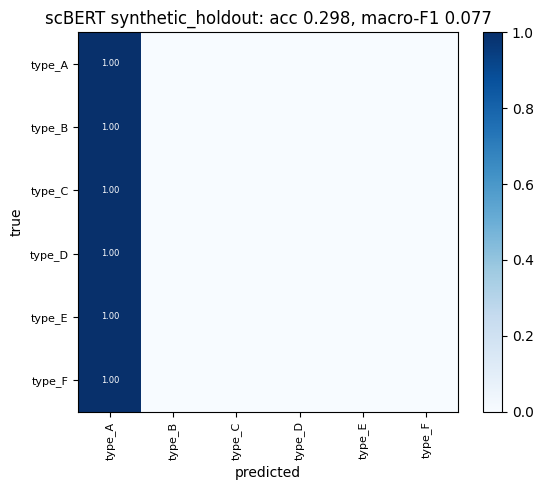


######## synthetic_v2: per-class test metrics
              precision  recall  f1-score  support
type_A              1.0     1.0       1.0    170.0
type_B              1.0     1.0       1.0    150.0
type_C              1.0     1.0       1.0    112.0
type_D              1.0     1.0       1.0     78.0
type_E              1.0     1.0       1.0     55.0
type_F              1.0     1.0       1.0     35.0
macro avg           1.0     1.0       1.0    600.0
weighted avg        1.0     1.0       1.0    600.0


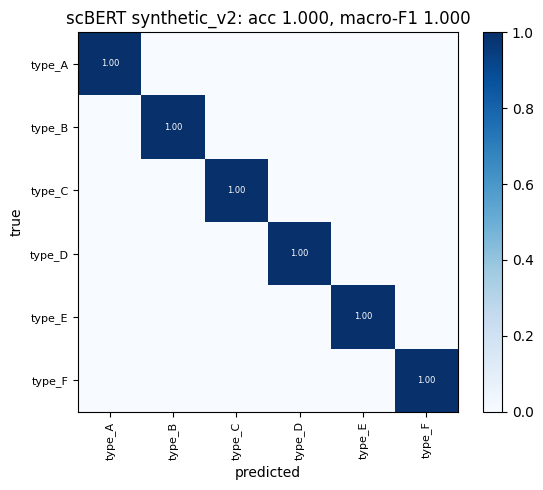


######## baron_holdout: per-class test metrics
                    precision  recall  f1-score  support
acinar                 0.9534  0.9583    0.9558    192.0
activated_stellate     0.8710  0.9474    0.9076     57.0
alpha                  0.9607  1.0000    0.9800    465.0
beta                   0.9729  0.9960    0.9843    505.0
delta                  0.9496  0.9417    0.9456    120.0
ductal                 0.9714  0.9488    0.9600    215.0
endothelial            0.9020  0.9200    0.9109     50.0
epsilon                0.0000  0.0000    0.0000      4.0
gamma                  1.0000  0.7451    0.8539     51.0
macrophage             1.0000  0.8182    0.9000     11.0
mast                   0.0000  0.0000    0.0000      5.0
quiescent_stellate     0.8065  0.7143    0.7576     35.0
schwann                0.0000  0.0000    0.0000      3.0
t_cell                 0.0000  0.0000    0.0000      1.0
macro avg              0.6705  0.6421    0.6540   1714.0
weighted avg           0.9503  0.9574   

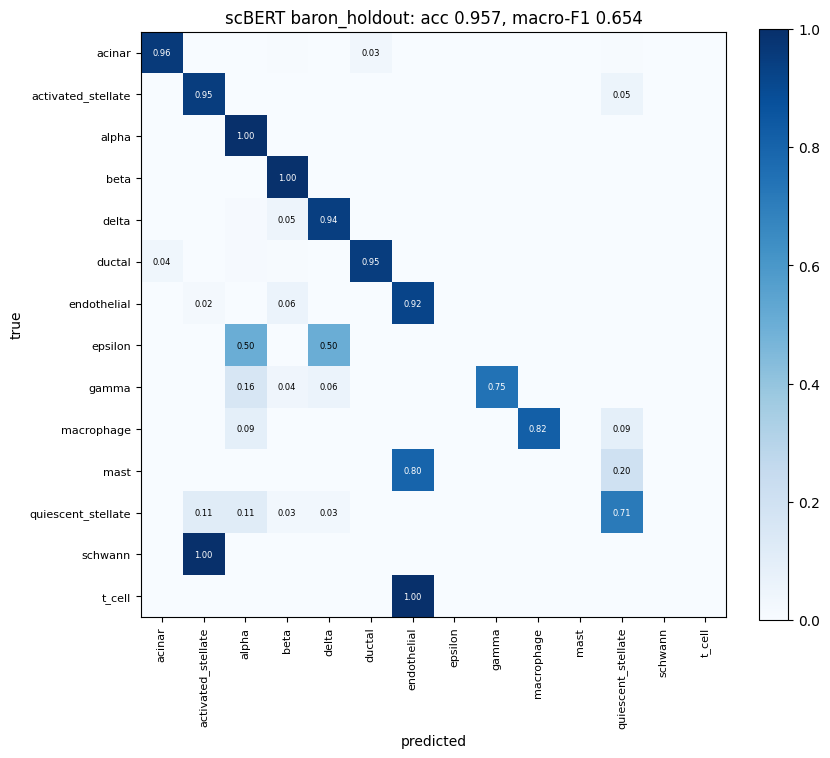


######## zheng_ref10: per-class test metrics
                              precision  recall  f1-score  support
CD14+ Monocyte                   0.0000  0.0000    0.0000    333.0
CD19+ B                          0.0000  0.0000    0.0000    687.0
CD34+                            0.0000  0.0000    0.0000     28.0
CD4+ T Helper2                   0.0000  0.0000    0.0000     11.0
CD4+/CD25 T Reg                  0.0000  0.0000    0.0000    723.0
CD4+/CD45RA+/CD25- Naive T       0.0000  0.0000    0.0000    219.0
CD4+/CD45RO+ Memory              0.0000  0.0000    0.0000    357.0
CD56+ NK                         0.0000  0.0000    0.0000   1026.0
CD8+ Cytotoxic T                 0.3224  0.9518    0.4817   2426.0
CD8+/CD45RA+ Naive Cytotoxic     0.5077  0.2190    0.3060   1945.0
Dendritic                        0.0000  0.0000    0.0000    245.0
macro avg                        0.0755  0.1064    0.0716   8000.0
weighted avg                     0.2212  0.3419    0.2205   8000.0


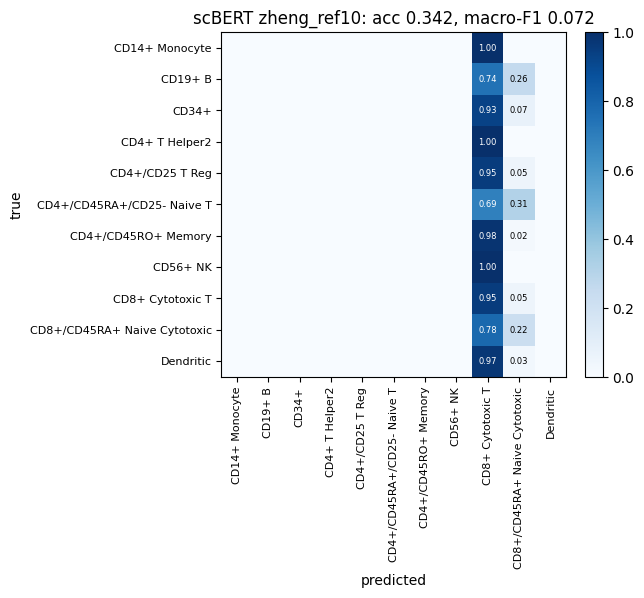


######## zheng_ref10_cont: per-class test metrics
                              precision  recall  f1-score  support
CD14+ Monocyte                   0.7928  0.7237    0.7567    333.0
CD19+ B                          0.9550  0.6492    0.7730    687.0
CD34+                            0.0000  0.0000    0.0000     28.0
CD4+ T Helper2                   0.0000  0.0000    0.0000     11.0
CD4+/CD25 T Reg                  0.6735  0.0456    0.0855    723.0
CD4+/CD45RA+/CD25- Naive T       0.0000  0.0000    0.0000    219.0
CD4+/CD45RO+ Memory              0.0000  0.0000    0.0000    357.0
CD56+ NK                         0.8319  0.8684    0.8498   1026.0
CD8+ Cytotoxic T                 0.5734  0.6892    0.6260   2426.0
CD8+/CD45RA+ Naive Cytotoxic     0.5593  0.8411    0.6719   1945.0
Dendritic                        0.6343  0.6939    0.6628    245.0
macro avg                        0.4564  0.4101    0.4023   8000.0
weighted avg                     0.6119  0.6361    0.5881   8000.0


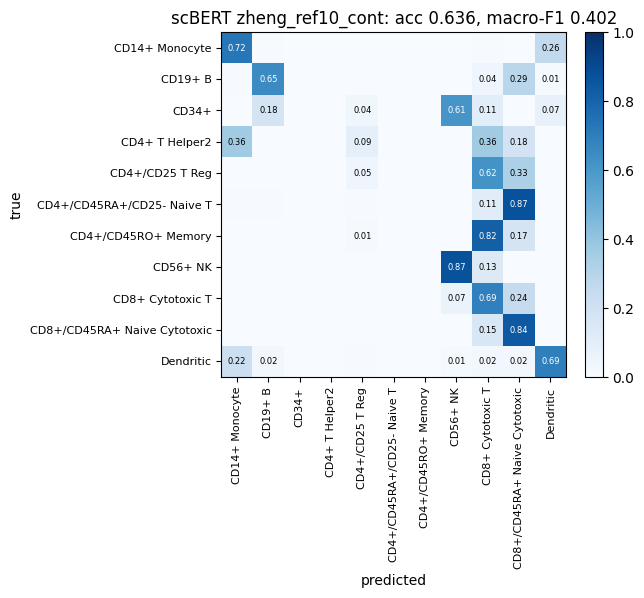


================ REPRODUCTION SUMMARY (test set) ================
       experiment  train cells  val cells  test cells  epochs  accuracy  macro precision  macro recall  macro F1  weighted F1  paper accuracy  Δ accuracy  paper macro F1  Δ macro F1
synthetic_holdout         1200        200         600       2    0.2983           0.0497        0.1667    0.0766       0.1371             NaN         NaN             NaN         NaN
     synthetic_v2         2000        300         600       4    1.0000           1.0000        1.0000    1.0000       1.0000             NaN         NaN             NaN         NaN
    baron_holdout         6355        500        1714       3    0.9574           0.6705        0.6421    0.6540       0.9530           0.975     -0.0176            0.86      -0.206
      zheng_ref10         6345        500        8000       3    0.3419           0.0755        0.1064    0.0716       0.2205           0.670     -0.3281             NaN         NaN
 zheng_ref10_cont      

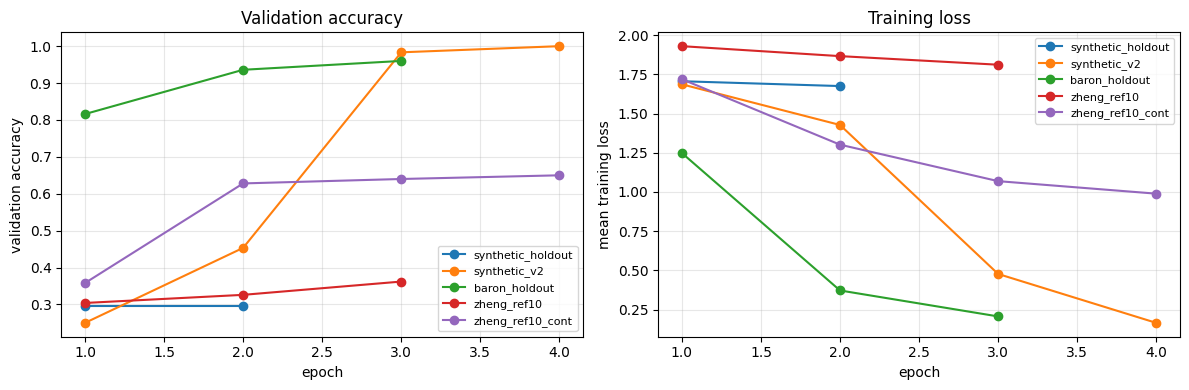

In [ ]:
import os, json, glob
import pandas as pd, numpy as np, matplotlib.pyplot as plt
RES = globals().get('RES', '/content/drive/MyDrive/scBERT_run/results')

PAPER = {
    'synthetic_holdout': (None,  None,  'no paper value; weak-signal synthetic (30 marker genes, ~3x)'),
    'synthetic_v2':      (None,  None,  'no paper value; stronger-signal synthetic'),
    'baron_holdout':     (0.975, 0.86,  'Fig. 2a / ED Fig. 2a, read from plot, 5-fold CV'),
    'zheng_ref10':       (0.67,  None,  'Fig. 2d at 10% reference, read from plot; ours: 3 epochs'),
    'zheng_ref10_cont':  (0.67,  None,  'Fig. 2d at 10% reference, read from plot; ours: 3 + 4 epochs'),
}

rows = []
for name, (pa, pf, src) in PAPER.items():
    mf = f'{RES}/{name}/fold0/metrics.json'
    if not os.path.exists(mf):
        print(f'{name}: not finished yet'); continue
    m = json.load(open(mf))
    rows.append({'experiment': name, 'train cells': m['n_fit'], 'val cells': m['n_val'], 'test cells': m['n_test'],
                 'epochs': m['epochs_run'],
                 'accuracy': m['test_accuracy'], 'macro precision': m['test_macro_precision'],
                 'macro recall': m['test_macro_recall'], 'macro F1': m['test_macro_f1'],
                 'weighted F1': m['test_weighted_f1'],
                 'paper accuracy': pa, 'Δ accuracy': None if pa is None else m['test_accuracy'] - pa,
                 'paper macro F1': pf, 'Δ macro F1': None if pf is None else m['test_macro_f1'] - pf,
                 'paper source': src})

    print(f'\n######## {name}: per-class test metrics')
    pc = pd.DataFrame({k: v for k, v in m['per_class'].items() if isinstance(v, dict)}).T
    print(pc.round(4).to_string())

    cm = np.array(m['confusion_matrix'], float); cmn = cm / cm.sum(1, keepdims=True).clip(min=1)
    L = m['labels']; fig, ax = plt.subplots(figsize=(max(6, .6 * len(L)), max(5, .55 * len(L))))
    im = ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(L))); ax.set_xticklabels(L, rotation=90, fontsize=8)
    ax.set_yticks(range(len(L))); ax.set_yticklabels(L, fontsize=8)
    for i in range(len(L)):
        for j in range(len(L)):
            if cmn[i, j] >= 0.01:
                ax.text(j, i, f'{cmn[i, j]:.2f}', ha='center', va='center', fontsize=6,
                        color='white' if cmn[i, j] > .5 else 'black')
    ax.set_xlabel('predicted'); ax.set_ylabel('true')
    ax.set_title(f'scBERT {name}: acc {m["test_accuracy"]:.3f}, macro-F1 {m["test_macro_f1"]:.3f}')
    fig.colorbar(im, fraction=.046); fig.tight_layout()
    fig.savefig(f'{RES}/{name}/confusion_matrix.png', dpi=200); plt.show()

table = pd.DataFrame(rows)
if len(table):
    table.to_csv(f'{RES}/reproduction_results.csv', index=False)
    pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
    print('\n================ REPRODUCTION SUMMARY (test set) ================')
    print(table.drop(columns=['paper source']).round(4).to_string(index=False))
    print('\npaper value sources:'); [print(f'  {r["experiment"]}: {r["paper source"]}') for r in rows]
    print(f'\nsaved {RES}/reproduction_results.csv and one confusion_matrix.png per experiment')

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for name in PAPER:
    mf = f'{RES}/{name}/fold0/metrics.json'
    if os.path.exists(mf):
        lg = json.load(open(mf))['log']; e = [l['epoch'] for l in lg]
        axs[0].plot(e, [l['val_acc'] for l in lg], marker='o', label=name)
        axs[1].plot(e, [l['train_loss'] for l in lg], marker='o', label=name)
axs[0].set(xlabel='epoch', ylabel='validation accuracy', title='Validation accuracy')
axs[1].set(xlabel='epoch', ylabel='mean training loss', title='Training loss')
for a in axs: a.grid(alpha=.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(f'{RES}/training_curves.png', dpi=200); plt.show()

In [ ]:
s = open('scbert_eval.py').read()
if '--init_from' not in s:
    s = s.replace("p.add_argument('--ckpt_every'", "p.add_argument('--init_from', default='', help='start fine-tuning from this fine-tuned best.pt')\np.add_argument('--ckpt_every'")
    s = s.replace("    if os.path.exists(state_p):  # resume", "    if args.init_from and not os.path.exists(state_p):\n        model.load_state_dict(torch.load(args.init_from, map_location='cpu', weights_only=True)); print('initialised from', args.init_from)\n    if os.path.exists(state_p):  # resume")
    open('scbert_eval.py', 'w').write(s)
print('patched OK' if open('scbert_eval.py').read().count('--init_from') == 1 else 'PATCH FAILED')

patched OK
